# 로지스틱 회귀
**목표: 로지스틱 회귀 알고리즘을 배우고 이진 분류 문제에서의 클래스 확률을 예측한다.**
- 예제: 생선의 크기, 무게 등이 주어졌을 때 7개의 생선에 대한 확률을 출력
- 길이, 높이, 두께 외에도 대각선 길이와 무게도 사용 가능

지금까지 배운 방법 중, K-최근접 이웃 방식을 사용하면 주변이웃의 비율을 확률로 표현할 수 있을 것이다.
## K- 최근접 이웃을 이용한 확률 구하기 예제
사이킷런의 knn 분류기는 샘플 주변 이웃의 클래스를 확률로 삼아 제공한다.\
데이터를 준비하고 확률를 계산해보자.

모델 훈련에 필요한 데이터는 Pandas를 이용해 csv 파일을 읽어올 것이다.\
`read_csv()`를 이용해 csv를 데이터프레임으로 가져온다.

In [39]:
import pandas as pd
fish = pd.read_csv("https://bit.ly/fish_csv_data")
fish.head() # 처음 5개의 줄 출력

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.5200,4.0200
1,Bream,290.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,26.5,31.1,12.3778,4.6961
3,Bream,363.0,29.0,33.5,12.7300,4.4555
4,Bream,430.0,29.0,34.0,12.4440,5.1340


생선의 종류는 데이터프레임의 `Species` 에 저장된다.\
해당 속성의 고유값들을 볼 때에는 `pands.unique()`를 이용해 출력한다.

In [40]:
print(pd.unique(fish['Species']))

['Bream' 'Roach' 'Whitefish' 'Parkki' 'Perch' 'Pike' 'Smelt']


총 7가지의 종류가 있다.\
이 데이터프레임에서 `Specis` 열을 타깃으로 만들고 나머지는 입력 데이터로 이용한다.\
데이터프레임에서 열을 선택하는 것은 중첩 리스트와 비숫하다.\
입력 데이터를 준비하기 위해 `Species`를 제외하고 나머지를 선택하겠다.

In [41]:
fish_input = fish[['Weight', 'Length', 'Diagonal', 'Height', 'Width']]

데이터프레임에서 여러 열을 선택하면 새로운 데이터프레임이 반환된다.\
해당 데이터프레임을 `fish_input`에 저장했다.\
저장한 데이터를 출력하면:

In [42]:
fish_input.head() # 처음 5줄 출력

,Weight,Length,Diagonal,Height,Width
0,242.0,25.4,30.0,11.5200,4.0200
1,290.0,26.3,31.2,12.4800,4.3056
2,340.0,26.5,31.1,12.3778,4.6961
3,363.0,29.0,33.5,12.7300,4.4555
4,430.0,29.0,34.0,12.4440,5.1340


입력 데이터가 모두 준비되었다.\
동일한 방법으로 타깃 데이터를 만들고 확인해보면:

In [43]:
fish_target = fish['Species']
print(fish_target)

0      Bream
1      Bream
2      Bream
3      Bream
4      Bream
       ...  
154    Smelt
155    Smelt
156    Smelt
157    Smelt
158    Smelt
Name: Species, Length: 159, dtype: object


> pandas 데이터프레임에서 하나의 열을 선택하면 데이터프레임이 아닌 pands series가 반환된다.
> 따라서, `Species`를 선택할 때 두 개의 대괄호로 선택하면 여러 개의 열을 선택한 것으로 데이터프레임으로 반환된다.

모델의 테스트 세트와 훈련 세트를 랜덤으로 나누는 `train_test_split`을 이용하겠다.

In [44]:
from sklearn.model_selection import train_test_split
train_input, test_input, train_target, test_target = train_test_split(fish_input, fish_target, random_state=42)

다음 사이킷런의 `StandardScaler`를 이용해 모델의 스케일을 표준점수로 전처리한다.
> 훈련값의 차이가 작지 않으므로 표준화 처리는 꼭 필요하다.

In [45]:
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
ss.fit(train_input)
train_scaled = ss.transform(train_input)
test_scaled = ss.transform(test_input)

데이터가 모두 준비되었다.\

`KNeighborsClassifier` 클래스의 인스턴스를 생성하고 훈련 세트와 테스트 세트의 점수를 우선 확인한다.\
`n_neighbors`를 3으로 변경하여 사용한다.

In [46]:
from sklearn.neighbors import KNeighborsClassifier
kn = KNeighborsClassifier(n_neighbors=3)
kn.fit(train_scaled, train_target)
print(kn.score(train_scaled, train_target))
print(kn.score(test_scaled, test_target))

0.8907563025210085
0.85


타깃 데이터를 만들 때 7개의 종류의 생선이 포함되어 있었으므로, 클래스 또한 7개가 된다.\
이와 같이 2개 이상의 클래스가 포함된 문제를 **다중 분류(multi-class classification)** 라고 부른다.

다만 이전까지 사용했던 두 클래스를 0과 1로 지정하는 이진 분류와 훈련 방식은 같다.\
다중 분류에서도 이렇게 각 클래스를 숫자로 지정하여 입력할 수 있지만, 사이킷런에서는 문자 그대로 입력이 가능하다.\
이 때, 주의할 점은 이전에 출력하였던 pandas 데이터프레임의 순서와는 다른 알파벳순으로 자동으로 정렬되어 훈련된다.
> `KNeighborsClassifier`에서 정렬된 타깃값은 `classes_` 속성에 저장되어 있다.

In [47]:
print(kn.classes_)

['Bream' 'Parkki' 'Perch' 'Pike' 'Roach' 'Smelt' 'Whitefish']


`'Bream'`이 첫 번째 이고, 알파벳순으로 `'Whitefish'`가 마지막이 된다.\
`predict()` 메소드 또한 결과값으로 문자 그대로를 출력한다.\

In [48]:
print(kn.predict(test_scaled[:5]))

['Perch' 'Smelt' 'Pike' 'Perch' 'Perch']


사이킷런의 분류 모델은 `predict_proba()` 메소드로 클래스별 확률값을 출력한다.\
테스트 세트에 있는 처음 5개의 샘플에 대한 확률을 출력하고 넘파이의 `round()` 함수를 이용하여 반올림해보겠다.
> `round()` 는 기본적으로 소수점 첫째 자리에서 반올림하는데, `decimals` 매개변수로 자릿수를 지정할 수 있다.

In [49]:
import numpy as np
proba = kn.predict_proba(test_scaled[:5])
print(np.round(proba, decimals=4)) # 소수점 네 번째 자리까지 표시(소수점 5번째 자리에서 반올림)

[[0.     0.     1.     0.     0.     0.     0.    ]
 [0.     0.     0.     0.     0.     1.     0.    ]
 [0.     0.     0.     1.     0.     0.     0.    ]
 [0.     0.     0.6667 0.     0.3333 0.     0.    ]
 [0.     0.     0.6667 0.     0.3333 0.     0.    ]]


행이 각 샘플이고, 열이 클래스별 확률이다.\
가장 가까운 이웃이 맞는지 확인하기 위해 `kn.kneighbors()` 메소드를 이용해 네 번째 샘플의 최근점 이웃 클래스를 확인하면:

In [50]:
distances, indexes = kn.kneighbors(test_scaled[3:4])
print(train_target.iloc[indexes[0]])

52     Roach
106    Perch
103    Perch
Name: Species, dtype: object


> `pandas`의 `iloc` 함수는 주어진 값을 정수 인덱스 값으로 변환하여 데이터프레임에서 행이나 열을 선택한다.
> 이 코드에서는 `indexes` 배열(104, 115, 106)을 활용해 `train_target`의 105, 106, 107번째 행을 실행한다.

이 샘플의 이웃은 다섯 번째 클래싄 `Roach`가 1개이고 세 번째 클래스인 `Perch` 가 2개이다.\
따라서 확률은 `Roach`의 경우 $\frac{1}{3} = 0.3333...$이고, `Perch`의 경우 $\frac{2}{3} = 0.6667...$이 된다.

이렇게 매우 쉽게 클래스들의 확률을 예측했다.\
분수 확률 계산들은 `predict_proba()` 메소드가 모두 진행해준다.

다만, 이러한 최근접 이웃 알고리즘들은 확률을 계산하기에는 무리가 있다.\
> 최근접 이웃에 경우, 참조하는 이웃의 수가 분모가 되고, 그 중 해당하는 클래스의 수가 분자로 고정된다.
따라서, 최근접 이웃 모델 대신 **로지스틱 회귀(Logistic regression)** 을 이용한다.\
이 모델 또한 선형 회귀(Linear Regression)와 비슷하게 회귀를 사용하긴 하지만 분류 모델이다.

# 로지스틱 회귀
로지스틱 회귀는 선형 회귀와 동일하게 선형 방정식을 학습한다.\
현제 데이터 세트에서의 예시:
$$z = a \times (Weight) + b \times (Length) + c \times (Diagonal) + d \times (Height) + e \times (Width) + F$$
여기서 $a, b, c, d, e, f$는 가중치 혹은 계수이다.\
특성은 늘어났지만 다중 회귀를 이용한 선형 방정식과 구조는 같다.\
$z$ 값은 무엇이든지 가능하다. 다만 확률을 계산하려면 $z$ 값은 0~1(또는 0~100%)사이 값이 되어야 한다.\
$z$가 음수로 무한대로 갈 때 0이 되고, 양수로 무한대로 갈 때 1이 되도록 바꾸면 된다.\
이를 위해 **시그모이드 함수(sigmoid function)**(또는 **로지스틱 함수(Logistic Function)**)를 이용한다.

## 시그모이드 함수 (Sigmoid Function) 또는 로지스틱 함수 (Logistic Function)
$z$ 값을 0과 1 사이의 값으로 압축하기 위해 **시그모이드 함수** (또는 **로지스틱 함수**)를 사용한다. 이 함수는 다음과 같이 정의된다:
$$\phi(z) = \frac{1}{1 + e^{-z}}$$
여기서 $e$는 자연상수이다. 시그모이드 함수는 어떤 입력값이든 0과 1 사이의 출력값으로 변환하며, $z$가 커질수록 1에 가까워지고, $z$가 작아질수록 0에 가까워지는 S자 형태의 곡선을 그린다. 이 특성 덕분에 확률을 모델링하는 데 적합하다.

간단한 시그모이드 함수 그래프 예시를 살펴보자.
>지수 함수 계산은 `np.exp()`를 사용한다.

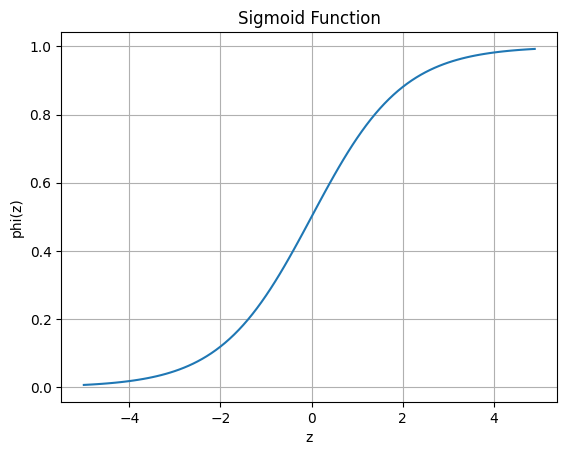

In [51]:
import matplotlib.pyplot as plt
import numpy as np
z = np.arange(-5, 5, 0.1)
phi = 1 / (1 + np.exp(-z))
plt.plot(z, phi)
plt.xlabel('z')
plt.ylabel('phi(z)')
plt.title('Sigmoid Function')
plt.grid()
plt.show()

선형 방정식에서 출력 $z$의 음수를 이용해 자연상수(자연로그의 밑) $e$를 거듭제곱하여 1을 더한 값의 역수를 취한다.\
위와 같은 그래프를 생성하여 결과값을 0과 1 사이의 부동소수점 값으로 변환할 수 있다.\

$z$가 무한히 큰 음수일 때는 이 함수는 0에 가까워지고, $z$가 무한히 큰 양수일 때에는 1에 가까워진다.\
$z$가 0이 될 때는 0.5가 된다. 따라서 $z$가 어떤 값이 되더라도 0~1 사이의 값이 된다.\
>이를 변환하여 백분율로 표현이 가능하다.

`LogisticRegression`을 이용해 로지스틱 회귀를 구현해보자.

# 이진 분류
본격적으로 훈련을 진행하기 전 간단한 이진 분류 모델을 훈련해보자. 시그모이드 함수의 출력이 `0.5`보다 크면 양성 클래스, `0.5`보다 작으면 음성 클래스로 판단한다.\
간단히 도미와 빙어 2개로 이진 분류를 수행하자.
> 시그모이드 함수의 출력이 정확히 `0.5`인 경우는 분류하는 경우에 따라 다른데, sklearn은 `0.5`일 때 음성 클래스로 판단한다.

## 방법
`numpy` 배열은 `True`, `False`의 불 값을 전달하여 행을 선택할 수 있다. 이를 **불리언 인덱싱(boolean indexing)** 라고 한다.\
다음 예시를 보면, `True`로 표시해둔 인덱스인 `'me'`만 출력되는 것을 알 수 있다.

In [52]:
char_arr = np.array(['me', 'you', 'you', 'me', 'you', 'me'])
print(char_arr[[True, False, False, True, False, True]])

['me' 'me' 'me']


이와 같은 방식을 사용해 훈련 세트에서 도미(`Bream`)과 빙어(`Smelt`)의 행만 골라내보자.\
비교 연산자 `or`(`|`)을 사용해 `Bream` 행과 `Smelt` 행이 모두 선택될 수 있게 하였다.\

In [53]:
bream_smelt_indexes = (train_target == "Bream") | (train_target == "Smelt") # train_target 타깃값 중 종류가 "Bream"이거나 "Smelt"인 물고기 찾기
train_input_bream_smelt_scaled = train_scaled[bream_smelt_indexes]
train_target_input_scaled_bream_smelt = train_target[bream_smelt_indexes]

`bream_smelt_indexes`는 도미와 빙어일 경우 `True`이고 나머지는 `False` 값이 들어가 있다.(인덱스 선택을 위한 불리언 인덱싱 리스트)\
따라서 이 배열을 사용해 `trian_scaled`와 `train_target`의 인덱스를 선택하면 도미와 빙어만 포함된 훈련 세트가 완성된다.

완성된 훈련 데이터를 이용해 로지스틱 회귀 모델을 훈련해보자.

In [54]:
from sklearn.linear_model import LogisticRegression
lr_bin = LogisticRegression()
lr_bin.fit(train_input_bream_smelt_scaled, train_target_input_scaled_bream_smelt)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

모델을 사용해 `train_input_bream_smelt_scaled`의 처음 5개 샘플을 예측해보자.

In [55]:
print(lr_bin.predict(train_input_bream_smelt_scaled[:5]))
print("# result should be:")
print(train_target_input_scaled_bream_smelt[:5])

['Bream' 'Smelt' 'Bream' 'Bream' 'Bream']
# result should be:
26     Bream
146    Smelt
22     Bream
11     Bream
27     Bream
Name: Species, dtype: object


기대값에 맞게 올바르게 예측했다.\
각 샘플의 확률은 knn과 같이 `predict_proba()` 에서 제공한다.

In [56]:
print(lr_bin.predict_proba(train_input_bream_smelt_scaled[:5]))

[[0.99760007 0.00239993]
 [0.02737325 0.97262675]
 [0.99486386 0.00513614]
 [0.98585047 0.01414953]
 [0.99767419 0.00232581]]


각 샘플마다 2개의 확률이 출력되었다.\
이진 분류의 경우 첫 번째 인덱스의 확률이 음성 클래스(`0`)의 확률, 두 번째 인덱스의 확률이 양성 클래스(`1`)의 확률이다.\
> 이 샘플의 경우 음성 클래스가 `Bream`, 양성 클래스가 `Smelt` 이다.
> 타깃값을 알파벳순으로 정렬하여 사용하므로 `B`가 첫 번째, `S`가 2번째이다.

In [57]:
print(lr_bin.classes_) # 타깃값을 알파벳순으로 정렬

['Bream' 'Smelt']


> 두 타깃값의 양/음성 여부를 변경하려면 직접 결과값을 0, 1로 지정한다.

## 결과
로지스틱 회귀(logistic regression)을 통해 성공적으로 이진 분류 모델을 훈련했다.\
로지스틱 회귀가 학습한 방정식 계수를 확인하면:

In [58]:
print(lr_bin.coef_, lr_bin.intercept_)

[[-0.40451732 -0.57582787 -0.66248158 -1.01329614 -0.73123131]] [-2.16172774]


따라서, 이 모델이 훈련한 방정식은 다음과 같다.\

- 로지스틱 방정식의 로짓 부분($z$)
$$
z = -2.16172774 - 0.40451732·x₁ - 0.57582787·x₂ - 0.66248158·x₃ - 1.01329614·x₄ - 0.73123131·x₅
$$

- 방정식 전체
$$
p = \frac{1}{1 + e^(2.16172774 + 0.40451732·x₁ + 0.57582787·x₂ + 0.66248158·x₃ + 1.01329614·x₄ + 0.73123131·x₅)}
$$

로짓 부분에 샘플들의 속성을 대입하여 해당 샘플의 로짓을 계산할 수 있다.\
`LogisticRegression`은 `decision_function()` 메소드로 로짓을 계산할 수 있다.

In [59]:
decisions = lr_bin.decision_function(train_input_bream_smelt_scaled[:5])
print(decisions)

[-6.02991358  3.57043428 -5.26630496 -4.24382314 -6.06135688]


이 로짓을 시그모이드 함수에 통과시키면 각 특성의 확률을 얻을 수 있다.\
`scipy` 라이브러리를 이용해 시그모이드 함수를 사용할 수 있다.
> `scipy.special`의 `expit`을 활용해 시그모이드 함수(로지스틱 함수)를 사용할 수 있다.

In [60]:
from scipy.special import expit
print(expit(decisions)) # decisions 로짓 값을 시그모이드 함수에 대입

[0.00239993 0.97262675 0.00513614 0.01414953 0.00232581]


이전의 로지스틱 회귀 모델의 확률값과 같게 출력되었다.\
출력하는 확률의 값은 양성 클래스에 대한 결과값을 반환한다.\
따라서, `decision_function()` 메소드는 양성 클래스의 로짓 값을 반환한다.

이제 본격적으로 7개의 클래스를 분류하는 다중 분류 문제로 넘어간다.

# 다중 분류
`LogisticRegression`을 이용해 다중 분류를 수행해보자.\
7개 종류의 클래스를 분류한다.

## 알고리즘 특성
로지스틱 회귀 모델은 일반적으로 반복적인 알고리즘을 사용한다.
> 반복 횟수를 `max_iter` 매개변수로 지정할 수 있다.
> `Lasso` 모델에서도 사용했다. 반복 계산을 통해 샘플에 대한 최적의 계수를 찾는 계산 수의 제한이다.

`max_iter` 매개변수의 기본값은 100이다. 이 데이터셋에서는 반복 횟수가 부족하므로 반복 횟수를 1000으로 늘인다.\
계수를 무작위 생성하고, 계수를 예측하고 손실과 기울기를 계산하여 수렴을 확인하는 과정을 반복한다.

로지스틱 회귀는 이진 분류를 위한 모델이지만, 기본적으로 각 샘플이 양성 클래스에 속할 확률을 출력한다. 이 문제에서는 확률값 자체가 필요하므로, 임계값을 적용한 클래스 레이블 대신 확률을 직접 사용한다.

또 로지스틱 회귀는 기본적으로 릿지 회귀와 같이 계수의 제곱을 규제한다.
> 이러한 규제를 L2 규제라고도 부른다.

릿지 회귀에서는 `alpha` 값을 규제 조절을 위해 사용했다. `alpha`가 커지면 규제도 커진다.\
로지스틱 회귀에서는 규제 제어 매개변수는 `C`이다.\
다만, **`C`는 `alpha`값과는 다르게 작을수록 규제가 커진다.**
`C`의 기본값은 1이다. 이 데이터셋에서는 규제를 완화하기 위해 규제 값을 20으로 줄이겠다.

## 훈련
스케일된 데이터 세트는 위에서 이미 준비했다.

In [61]:
lr = LogisticRegression(C=20, max_iter=1000)
lr.fit(train_scaled, train_target)
print(lr.score(train_scaled, train_target)) # 훈련 세트
print(lr.score(test_scaled, test_target)) # 테스트 세트

0.9327731092436975
0.925


과대적합, 과소적합 모두 해당되지 않는다.\
> 로지스틱 회귀 모델의 평가 방법은 매우 복잡하다.


처음 5개 샘플에 대한 예측을 생성해보면:

In [62]:
print(lr.predict(test_scaled[:5]))
print(test_target[:5])

['Perch' 'Smelt' 'Pike' 'Roach' 'Perch']
78         Perch
155        Smelt
128         Pike
55     Whitefish
94         Perch
Name: Species, dtype: object


예측 또한 정상적으로 출력되었다.\
예측 확률을 출력해보면:

In [63]:
proba = lr.predict_proba(test_scaled[:5])
print(lr.classes_)
print(np.round(proba, decimals=3)) # 네 번째 자리에서 반올림하여 3번째 자리까지 표현

['Bream' 'Parkki' 'Perch' 'Pike' 'Roach' 'Smelt' 'Whitefish']
[[0.    0.014 0.842 0.    0.135 0.007 0.003]
 [0.    0.003 0.044 0.    0.007 0.946 0.   ]
 [0.    0.    0.034 0.934 0.015 0.016 0.   ]
 [0.011 0.034 0.305 0.006 0.567 0.    0.076]
 [0.    0.    0.904 0.002 0.089 0.002 0.001]]


5개 샘플에 대한 예측이므로 5개의 열, 7개의 클래스므로 7개의 행이 생성되었다.\
첫 번째 샘플에서 `Perch` 클래스에 대한 확률이 84.2%로 가장 높다. 따라서, `Perch` 클래스로 분류되었다.\
7개의 클래스중 확률이 가장 높은 클래스가 결과값이 된다.

## 방정식
이 모델이 학습한 방정식을 확인해보자.

In [64]:
print(lr.coef_, lr.intercept_)

[[-1.50605455 -1.03747913  2.60919713  7.69422739 -1.18603342]
 [ 0.19200047 -1.99988812 -3.79617725  6.50312639 -2.00022754]
 [ 3.55793539  6.36988929 -8.52233732 -5.75397233  3.79233438]
 [-0.11453308  3.61060121  3.94464503 -3.62243904 -1.75981679]
 [-1.40843717 -6.09242191  5.28629633 -0.86696569  1.84518455]
 [-1.33419951  1.48153392  1.38217547 -5.6602348  -4.39228963]
 [ 0.61328846 -2.33223527 -0.90379939  1.70625807  3.70084846]] [-0.10345046 -0.27281217  3.24444852 -0.17565069  2.64960025 -6.72042852
  1.37829306]


7개의 특성 샘플에 대한 모든 특성을 계산했다.

In [65]:
print(lr.coef_.shape, lr.intercept_.shape)

(7, 5) (7,)


7개의 행이 존재하므로 로짓 값을 각각의 클래스마다 모두 계산한 것을 확인할 수 있다.\
각각의 로짓 값 중 가장 높은 확률 결과를 표시하는 클래스가 예측 클래스가 된다.

이진 분류에서는 시그모이드 함수를 이용하여 확률을 0과 1 사이의 값으로 분류했지만,\
다중 분류의 경우 **소프트맥스 함수(Softmax Fucntion)** 를 사용하여 7개의 로짓을 확률로 반환한다.
> 시그모이드 함수는 하나의 선형 방정식의 출력을 0과 1 사이의 값으로 변환한다.\
> 이와 달리 소프트맥스는 여러 개의 선형 방정식의 출력을 0과 1 사이의 확률로 압축하고 전체 합이 1이 되로록 한다.\
> 시그모이드 함수는 각 클래스마다 0과 1 사이의 확률을 구하고, 소프트맥스 함수는 모든 클래스의 확률을 0과 1 사이의 값으로 변환하고 모든 합이 1이 되도록 한다.
> 일반적으로 max 함수들은 최댓값 하나를 선택하지만, 소프트맥스는 최댓값에 높은 확률을 할당하면서도 다른 클래스에도 확률을 부여한다.\
> 그래서 softmax, 유연화된 max 함수이다. 이를 위해 지수함수를 사용하기도 하므로 **정규화된 지수 함수**라고도 부른다.

소프트맥스 함수의 7개의 로짓 값을 $z_1$에서 $z_7$로 지정한다.\
$z_1$~$z_7$의 값을 이용해 지수 함수 $e^{z_1}$~$e^{z_7}$을 모두 계산하여 더한다.

$$
e_{sum} = e^{z_1} + e^{z_2} + e^{z_3} + e^{z_4} + e^{z_5} + e^{z_6} + e^{z_7}
$$

또는 시그마 표기법으로:

$$
e_{sum} = \sum_{i=1}^{7} e^{z_i}
$$

다음 $e^{z_1}$~$e^{z_7}$를 각각 $e_{sum}$으로 나눈다.

$$
p_1 = \frac{e^{z_1}}{e_{sum}}, \quad p_2 = \frac{e^{z_2}}{e_{sum}}, \quad p_3 = \frac{e^{z_3}}{e_{sum}}, \quad p_4 = \frac{e^{z_4}}{e_{sum}}, \quad p_5 = \frac{e^{z_5}}{e_{sum}}, \quad p_6 = \frac{e^{z_6}}{e_{sum}}, \quad p_7 = \frac{e^{z_7}}{e_{sum}}
$$

또는 일반화된 형태로:

$$
p_i = \frac{e^{z_i}}{e_{sum}} = \frac{e^{z_i}}{\sum_{j=1}^{7} e^{z_j}}, \quad i = 1, 2, ..., 7
$$

$p_1$에서 $p_7$까지 모두 더하면 분자와 문모가 같아지므로 1이 된다.
> 시그모이드 함수와 소프트맥스 함수는 딥러닝 신경망을 다루는 문서에서 다시 참조된다.

## 확률로 변환
이진 분류에서처럼 `decision_function()` 메소드로 $p_1$에서 $p_7$까지의 값을 모두 구한 다음 소프트맥스 함수를 이용해 확률로 변환해보자.

In [66]:
decisions_softmax = lr.decision_function(test_scaled[:5])
print(np.round(decisions_softmax, decimals=2)) # 소수점 3번째에서 반올림

[[ -6.51   1.04   5.17  -2.76   3.34   0.35  -0.63]
 [-10.88   1.94   4.78  -2.42   2.99   7.84  -4.25]
 [ -4.34  -6.24   3.17   6.48   2.36   2.43  -3.87]
 [ -0.69   0.45   2.64  -1.21   3.26  -5.7    1.26]
 [ -6.4   -1.99   5.82  -0.13   3.5   -0.09  -0.7 ]]


`scipy`의 `scipy.special` 클래스 아래의 `softmax()` 메소드를 이용한다.

In [67]:
from scipy.special import softmax
proba_softmax = softmax(decisions_softmax, axis=1)
print(np.round(proba_softmax, decimals=3)) # 소수점 4번째에서 반올림

[[0.    0.014 0.842 0.    0.135 0.007 0.003]
 [0.    0.003 0.044 0.    0.007 0.946 0.   ]
 [0.    0.    0.034 0.934 0.015 0.016 0.   ]
 [0.011 0.034 0.305 0.006 0.567 0.    0.076]
 [0.    0.    0.904 0.002 0.089 0.002 0.001]]


`decisions_softmax`의 로짓 값을 `softmax()` 메소드로 전달했다.
> `softmax()` 함수의 `axis=` 매개변수는 각 행, 즉 각 샘플에 대한 소프트맥스를 계산한다.\
> 1인 경우 행 방향, 0인 경우 열 방향으로 계산한다. 자세한 내용은 `scipy`의 문서를 참조한다.
> [문서](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.softmax.html)


# 정리
데이터를 스케일링하고 `pandas` 데이터프레임으로 묶었다.\
초기하는 knn 모델이 구하는 확률을 이용하려 했지만, 이웃한 샘플의 클래스 비율이므로 항상 정해진 확률만 출력한다.\
따라서 로지스틱 회귀 모델의 특징을 이용해 확률을 구한다.\

분류 모델인 로지스틱 회귀가 결과값을 0과 1 사이의 값을 리턴함을 이용해 이것을 0~100 사이의 확률로 이해할 수 있다.
이를 이용해 확률을 계산한다.

이진 분류인 경우 시그모이드 함수를 이용하여 0~1 사이의 출력값을 만든다.\
음성 클래스의 경우 1에서 양성 클래스의 확률을 빼면 된다.

다중 분류의 경우 클래스 개수만큼 로짓을 훈련한다. 그다음 각 로짓을 소프트맥스 함수를 이용해 전체 클래스에 대한 합이 1이 되도록 만든다.\
이 값을 각 클래스에 대한 확률로 이해할 수 있다.

로지스틱 회귀 sklearn 
[문서](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)

`solver` 매개변수에서 사용할 로지스틱 회귀 알고리즘을 선택할 수 있다.\
기본값은 `lbfgs`이다. 0.17에서 추가된 `sag`는 확률적 경사 하강법(04-2.ipynb)알고리즘을 활용하여 특성과 샘플 수가 많을 때 성능이 좋다.\
0.19에 추가된 `saga`는 `sag`의 개선 버전이다.\
1.2에서는 뉴턴 방법과 숄레스키 분해를 결합하여 대규모 데이터셋에 적합한 `newton-cholesky`가 추가되었다.

`penalty` 매개변수에서 L2규제(릿지 규제)와 L1규제(라쏘 규제)를 선택할 수 있다.\
기본값은 L2 규제이다.

`C`에서는 규제의 강도를 정할 수 있다. 값이 작을수록 규제가 세진다.